# EDA

## 1. Load the data

We use the metadata prepared in `00_data.ipynb`. Target counts exclude ignored regions,
and test frames remain unlabeled. All sizes below refer to original-image pixels.

In [39]:
import json
import sys
from io import BytesIO
from pathlib import Path

import numpy as np
import plotly.express as px
import plotly.io
import polars as pl
from IPython.display import Image as DisplayImage
from IPython.display import Markdown, display
from PIL import Image, ImageDraw

working_directory = Path.cwd().resolve()

REPOSITORY_ROOT = next(
    (
        directory
        for directory in (working_directory, *working_directory.parents)
        if (directory / "pyproject.toml").is_file() and (directory / "src/hm2").is_dir()
    )
)

METADATA_DIRECTORY = REPOSITORY_ROOT / "data/metadata"

sys.path.insert(0, str(REPOSITORY_ROOT / "src"))

SEED = 2026

pl.Config.set_tbl_rows(12)

pl.Config.set_tbl_cols(12)

from hm2.data import CLASS_NAMES, compare_yolo_coco, read_yolo_boxes, xywh_to_yolo, yolo_to_xywh
from hm2.visualization import CLASS_COLORS, draw_crop, draw_frame, draw_frame_pair

manifest_path = METADATA_DIRECTORY / "manifest.json"

if not manifest_path.is_file():
    raise FileNotFoundError("Run 00_data.ipynb before this notebook.")

manifest = json.loads(manifest_path.read_text())

dataset_root = Path(manifest["dataset_root"])

for name, signature in manifest["sources"].items():
    stat = (dataset_root / name).stat()
    if (stat.st_size, stat.st_mtime_ns) != (signature["size"], signature["mtime_ns"]):
        raise ValueError(f"Source metadata changed: {name}. Rerun 00_data.ipynb.")

frames = pl.read_parquet(METADATA_DIRECTORY / "frames.parquet")

objects = pl.read_parquet(METADATA_DIRECTORY / "objects.parquet")

ignored_regions = pl.read_parquet(METADATA_DIRECTORY / "ignored_regions.parquet")

labeled_frames = frames.filter(pl.col("is_labeled"))

colors = dict(zip(CLASS_NAMES, CLASS_COLORS))

plotly.io.renderers.default = "plotly_mimetype"


def display_image(image: Image.Image) -> None:
    buffer = BytesIO()
    image.save(buffer, format="JPEG", quality=50, optimize=True)
    display(DisplayImage(data=buffer.getvalue()))


frames.group_by("split").agg(
    pl.len().alias("Frames"), pl.col("clip").n_unique().alias("Clips"), pl.col("is_labeled").first()
).sort("split")

split,Frames,Clips,is_labeled
str,u32,u32,bool
"""test""",3811,48,false
"""train""",24201,56,true
"""val""",2846,7,true


In [40]:
pl.DataFrame({"Class ID": range(8), "COCO category ID": range(1, 9), "Class": CLASS_NAMES})

Class ID,COCO category ID,Class
i64,i64,str
0,1,"""person"""
1,2,"""bicycle"""
2,3,"""car"""
3,4,"""van"""
4,5,"""truck"""
5,6,"""tricycle"""
6,7,"""bus"""
7,8,"""motor"""


In [41]:
pl.read_csv(METADATA_DIRECTORY / "integrity.csv")

check,count,is_pass
str,i64,bool
"""Duplicate image keys""",0,true
"""Duplicate split image IDs""",0,true
"""Duplicate annotation IDs""",0,true
"""Annotations with unknown image…",0,true
"""Missing image files""",0,true
"""Images absent from metadata""",0,true
…,…,…
"""Missing sample submission""",1,false
"""Invalid image dimensions""",0,true


In [42]:
train_clips = set(frames.filter(pl.col("split") == "train")["clip"])

val_clips = set(frames.filter(pl.col("split") == "val")["clip"])

overlapping_clips = sorted(train_clips & val_clips)

pl.DataFrame(
    {
        "Train clips": [len(train_clips)],
        "Validation clips": [len(val_clips)],
        "Overlapping clips": [len(overlapping_clips)],
    }
)

Train clips,Validation clips,Overlapping clips
i64,i64,i64
56,7,0


In [43]:
if overlapping_clips:
    raise ValueError("Train and validation share clips. Investigate before experiments.")

The official validation split stays separate. Neighboring frames can show the same
objects and background, so a random frame split could leak sequence information.
Any later internal folds must group by clip.

## 2. Visual overview

We choose examples from metadata with seed 2026. The criteria cover sparse and crowded
scenes, tiny boxes, recorded occlusion, ignored regions, and the rarest observed class.
Duplicate selections are shown once. Magenta translucent regions are ignored areas.
They are not background negatives. Dense views use colors without repeated text labels.

**Sparse scene.** `train/uav0000263_03289_v/0000457`, 1904 × 1071 px, 1 targets.

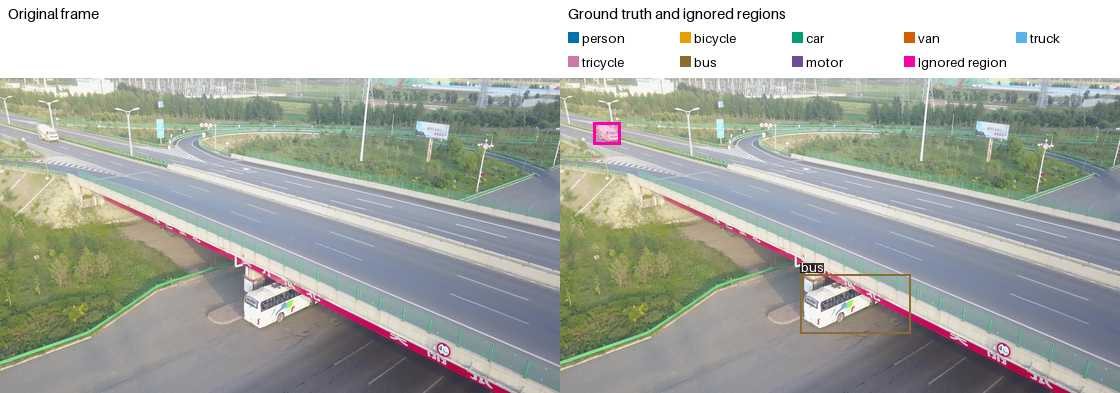

**Crowded scene.** `train/uav0000295_02300_v/0000322`, 2720 × 1530 px, 180 targets.

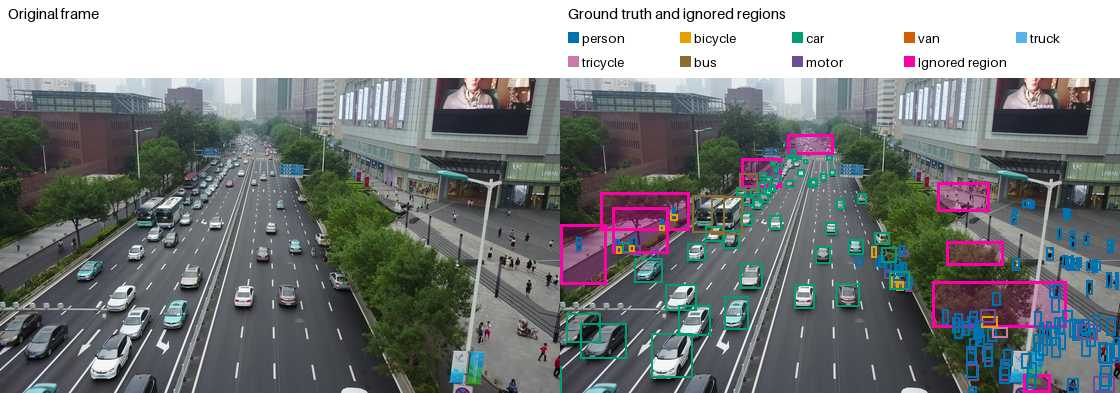

**Tiny objects.** `train/uav0000124_00944_v/0000001`, 2688 × 1512 px, 120 targets.

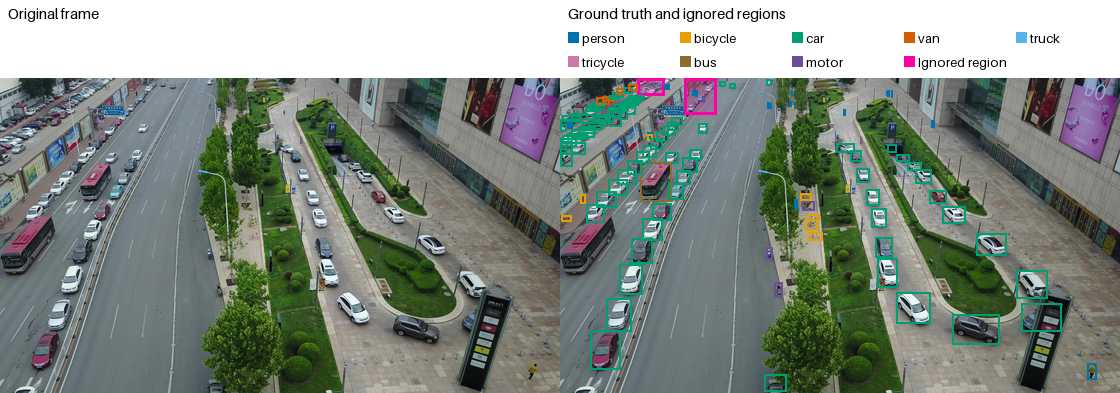

**High recorded occlusion code.** `train/uav0000288_00001_v/0000918`, 1904 × 1071 px, 61 targets.

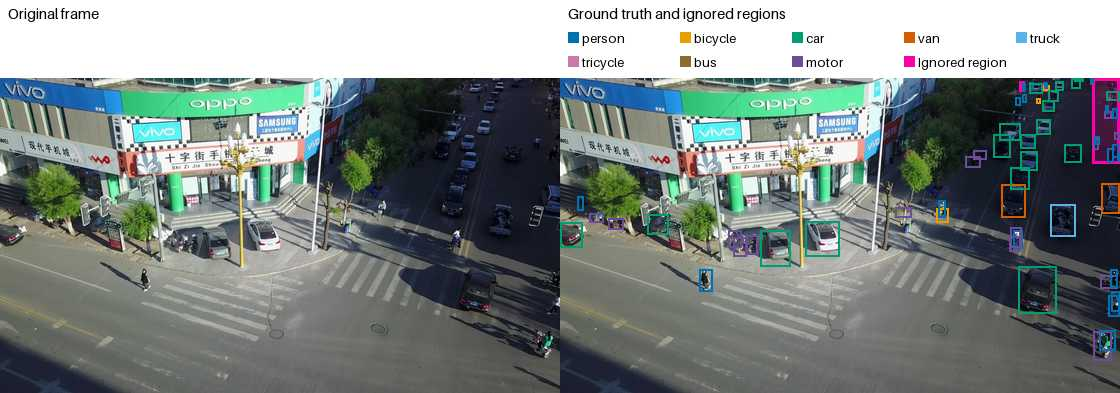

**Ignored regions.** `train/uav0000126_00001_v/0000322`, 2688 × 1512 px, 166 targets.

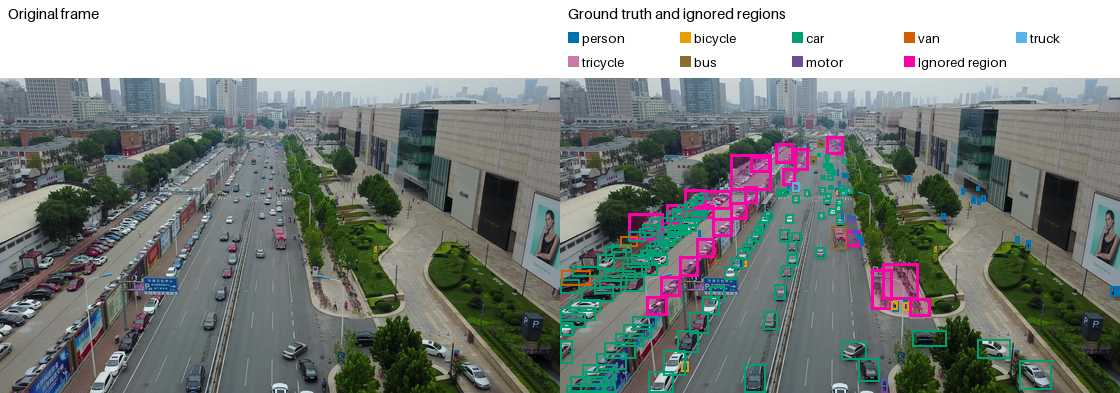

**Rare class: bus.** `train/uav0000264_02760_v/0000485`, 1904 × 1071 px, 20 targets.

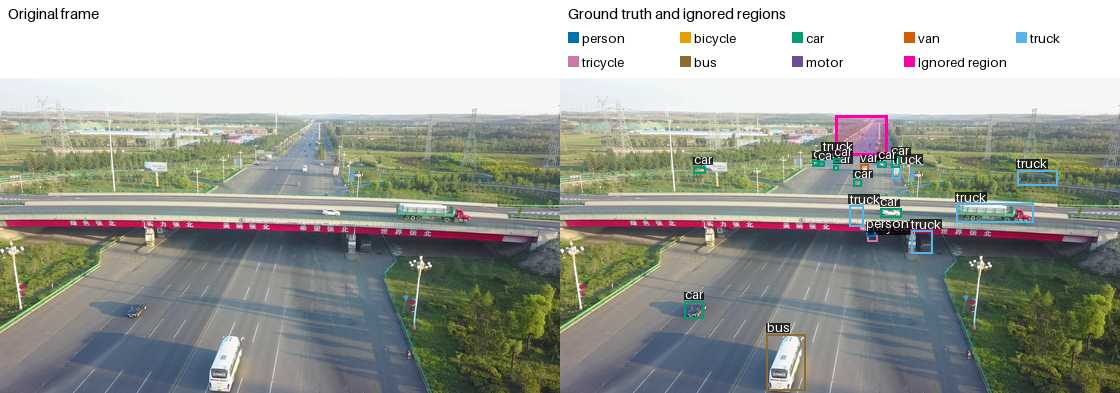

Reason,Image,Targets,Ignored regions
str,str,i64,i64
"""Sparse scene""","""train/uav0000263_03289_v/00004…",1,1
"""Crowded scene""","""train/uav0000295_02300_v/00003…",180,9
"""Tiny objects""","""train/uav0000124_00944_v/00000…",120,2
"""High recorded occlusion code""","""train/uav0000288_00001_v/00009…",61,3
"""Ignored regions""","""train/uav0000126_00001_v/00003…",166,22
"""Rare class: bus""","""train/uav0000264_02760_v/00004…",20,1


In [2]:
frame_sizes = objects.group_by("image_key").agg(
    pl.col("area").min().alias("min_area"),
    pl.col("occlusion").max().alias("max_occlusion"),
)
candidates = labeled_frames.join(frame_sizes, on="image_key", how="left").sample(
    fraction=1.0, shuffle=True, seed=SEED
)
rare_class = objects.group_by("class_name").len().sort("len", "class_name")["class_name"][0]
rare_keys = objects.filter(pl.col("class_name") == rare_class)["image_key"].unique().sort()
selections = [
    ("Sparse scene", candidates.filter(pl.col("target_count") > 0).sort("target_count").head(1)),
    ("Crowded scene", candidates.sort("target_count", descending=True).head(1)),
    ("Tiny objects", candidates.filter(pl.col("min_area").is_not_null()).sort("min_area").head(1)),
    (
        "High recorded occlusion code",
        candidates.filter(pl.col("max_occlusion").is_not_null())
        .sort("max_occlusion", descending=True)
        .head(1),
    ),
    (
        "Ignored regions",
        candidates.filter(pl.col("ignore_count") > 0).sort("ignore_count", descending=True).head(1),
    ),
    (
        f"Rare class: {rare_class}",
        candidates.filter(pl.col("image_key").is_in(rare_keys.implode())).head(1),
    ),
]
shown_keys = set()
selected_records = []
for reason, selection in selections:
    if selection.is_empty():
        continue
    record = selection.row(0, named=True)
    if record["image_key"] in shown_keys:
        continue
    shown_keys.add(record["image_key"])
    selected_records.append(
        {
            "Reason": reason,
            "Image": record["image_key"],
            "Targets": record["target_count"],
            "Ignored regions": record["ignore_count"],
        }
    )
    display(
        Markdown(
            f"**{reason}.** `{record['image_key']}`, "
            f"{record['image_width']} × {record['image_height']} px, "
            f"{record['target_count']} targets."
        )
    )
    display_image(
        draw_frame_pair(
            dataset_root / record["relative_path"],
            objects.filter(pl.col("image_key") == record["image_key"]),
            ignored_regions.filter(pl.col("image_key") == record["image_key"]),
            panel_width=560,
            should_label=record["target_count"] <= 60,
        )
    )
pl.from_dicts(selected_records)

## 3. Class distribution

We count target boxes, not unique tracked objects. The same tracked object can appear
in many frames. The table retains all eight classes, including a zero count if needed.

In [44]:
classes = pl.DataFrame({"class_id": range(8), "class_name": CLASS_NAMES})

split_classes = pl.DataFrame({"split": ["train", "val"]}).join(classes, how="cross")

class_counts = (
    split_classes.join(
        objects.group_by("split", "class_id", "class_name").len(name="count"),
        on=["split", "class_id", "class_name"],
        how="left",
    )
    .with_columns(pl.col("count").fill_null(0))
    .with_columns((pl.col("count") / pl.col("count").sum().over("split")).alias("proportion"))
    .sort("split", "class_id")
)

class_counts

split,class_id,class_name,count,proportion
str,i64,str,u32,f64
"""train""",0,"""person""",328701,0.297328
"""train""",1,"""bicycle""",40255,0.036413
"""train""",2,"""car""",505301,0.457073
"""train""",3,"""van""",46940,0.04246
"""train""",4,"""truck""",30498,0.027587
"""train""",5,"""tricycle""",41349,0.037402
…,…,…,…,…
"""val""",2,"""car""",31821,0.278809
"""val""",3,"""van""",6842,0.059948


In [45]:
px.bar(
    class_counts,
    x="class_name",
    y="count",
    color="split",
    barmode="group",
    category_orders={"class_name": list(CLASS_NAMES)},
    labels={"class_name": "Class", "count": "Target annotations", "split": "Split"},
    title="Target class counts by split",
)

In [46]:
overall_classes = classes.join(
    objects.group_by("class_id").len(name="count"), on="class_id", how="left"
).with_columns(pl.col("count").fill_null(0))

overall_classes = overall_classes.with_columns(
    (pl.col("count") / pl.col("count").sum()).alias("proportion")
)

overall_classes

class_id,class_name,count,proportion
i64,str,u32,f64
0,"""person""",379013,0.310756
1,"""bicycle""",46277,0.037943
2,"""car""",537122,0.440391
3,"""van""",53782,0.044096
4,"""truck""",31857,0.02612
5,"""tricycle""",46836,0.038401
6,"""bus""",9917,0.008131
7,"""motor""",114844,0.094162


In [47]:
clip_class_counts = objects.group_by("split", "clip", "class_name").len(name="count")

clip_grid = (
    labeled_frames.select("split", "clip").unique().join(classes.select("class_name"), how="cross")
)

clip_proportions = (
    clip_grid.join(clip_class_counts, on=["split", "clip", "class_name"], how="left")
    .with_columns(pl.col("count").fill_null(0))
    .with_columns(
        (pl.col("count") / pl.col("count").sum().over("split", "clip"))
        .fill_nan(0)
        .alias("proportion"),
        (pl.col("split") + "/" + pl.col("clip")).alias("clip_label"),
    )
    .sort("clip_label")
)

px.density_heatmap(
    clip_proportions,
    x="class_name",
    y="clip_label",
    z="proportion",
    histfunc="sum",
    color_continuous_scale="Blues",
    height=950,
    category_orders={"class_name": list(CLASS_NAMES)},
    labels={"class_name": "Class", "clip_label": "Clip", "proportion": "Within-clip fraction"},
    title="Class proportions vary across labeled clips",
)

## 4. Object sizes

We compare width, height, area, and aspect ratio in original-image pixels. The area
distribution is aggregated before plotting, so the notebook does not embed every box.
Small means area below 32² px², medium means 32² to below 96² px², and large means
at least 96² px². These bins describe source boxes and do not measure detector quality.

In [48]:
size_quantiles = (
    objects.group_by("class_name")
    .agg(
        pl.len().alias("Objects"),
        pl.col("width").median().alias("Median width px"),
        pl.col("height").median().alias("Median height px"),
        pl.col("area").quantile(0.1).alias("Area p10 px²"),
        pl.col("area").median().alias("Median area px²"),
        pl.col("area").quantile(0.9).alias("Area p90 px²"),
        pl.col("aspect_ratio").quantile(0.1).alias("Aspect ratio p10"),
        pl.col("aspect_ratio").median().alias("Median aspect ratio"),
        pl.col("aspect_ratio").quantile(0.9).alias("Aspect ratio p90"),
    )
    .sort("Objects", descending=True)
)

size_quantiles

class_name,Objects,Median width px,Median height px,Area p10 px²,Median area px²,Area p90 px²,Aspect ratio p10,Median aspect ratio,Aspect ratio p90
str,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""car""",537122,68.0,48.0,806.0,3312.0,14823.0,0.817308,1.260274,2.436782
"""person""",379013,26.0,51.0,420.0,1344.0,3969.0,0.367647,0.5,0.761905
"""motor""",114844,37.0,43.0,414.0,1584.0,4697.0,0.507042,0.804878,1.538462
"""van""",53782,57.0,47.0,825.0,2630.0,16530.0,0.706767,1.130791,1.966667
"""tricycle""",46836,58.0,51.0,624.0,2970.0,10900.0,0.659574,1.055556,1.815789
"""bicycle""",46277,47.0,45.0,667.0,1924.0,5723.0,0.512605,0.925926,1.737705
"""truck""",31857,81.0,69.0,1100.0,5467.0,32922.0,0.773585,1.08,2.302752
"""bus""",9917,123.0,103.0,1750.0,12470.0,70057.0,0.61828,1.046875,2.898876


In [49]:
size_fractions = (
    objects.group_by("split", "size_group")
    .len(name="count")
    .with_columns((pl.col("count") / pl.col("count").sum().over("split")).alias("fraction"))
)

size_fractions.sort("split", "size_group")

split,size_group,count,fraction
str,str,u32,f64
"""train""","""Large""",128165,0.115932
"""train""","""Medium""",702004,0.635001
"""train""","""Small""",275347,0.249066
"""val""","""Large""",12865,0.11272
"""val""","""Medium""",79357,0.695309
"""val""","""Small""",21910,0.191971


In [50]:
area_distribution = (
    objects.filter(pl.col("area") > 0)
    .with_columns(((pl.col("area").log10() * 4).floor() / 4).alias("log_bin"))
    .group_by("split", "log_bin")
    .len(name="count")
    .with_columns((10 ** (pl.col("log_bin") + 0.125)).alias("area_px2"))
    .sort("split", "area_px2")
)

px.line(
    area_distribution,
    x="area_px2",
    y="count",
    color="split",
    log_x=True,
    labels={
        "area_px2": "Box area (px², logarithmic bins)",
        "count": "Target annotations",
        "split": "Split",
    },
    title="Box area distribution in original images",
)

In [51]:
shape_distribution = (
    objects.filter((pl.col("width") > 0) & (pl.col("height") > 0))
    .with_columns(
        (pl.col("width").log10() * 4).floor().alias("width_bin"),
        (pl.col("height").log10() * 4).floor().alias("height_bin"),
    )
    .group_by("width_bin", "height_bin")
    .len(name="count")
    .with_columns(
        (10 ** ((pl.col("width_bin") + 0.5) / 4)).alias("width_px"),
        (10 ** ((pl.col("height_bin") + 0.5) / 4)).alias("height_px"),
    )
)

px.scatter(
    shape_distribution,
    x="width_px",
    y="height_px",
    size="count",
    color="count",
    log_x=True,
    log_y=True,
    color_continuous_scale="Blues",
    size_max=30,
    labels={
        "width_px": "Box width (px)",
        "height_px": "Box height (px)",
        "count": "Annotations in bin",
    },
    title="Box widths and heights across labeled frames",
)

In [52]:
per_clip_sizes = objects.group_by("split", "clip").agg(
    pl.col("area").median().alias("Median area px²"),
    (pl.col("size_group") == "Small").mean().alias("Small-object fraction"),
)

per_clip_sizes.sort("Small-object fraction", descending=True).head(8)

split,clip,Median area px²,Small-object fraction
str,str,f64,f64
"""train""","""uav0000248_00001_v""",899.0,0.730889
"""train""","""uav0000239_12336_v""",600.0,0.651825
"""train""","""uav0000264_02760_v""",961.0,0.544727
"""train""","""uav0000278_00001_v""",992.0,0.510743
"""val""","""uav0000182_00000_v""",1053.0,0.491596
"""train""","""uav0000239_03720_v""",1110.0,0.478311
"""train""","""uav0000279_00001_v""",1113.0,0.475659
"""train""","""uav0000145_00000_v""",1464.0,0.462029


We also inspect typical small targets at 4× magnification. For each represented class,
We choose the small box nearest that class's median small-object area. Each crop retains
source pixel coordinates and a red target outline. Magnification adds no image detail.

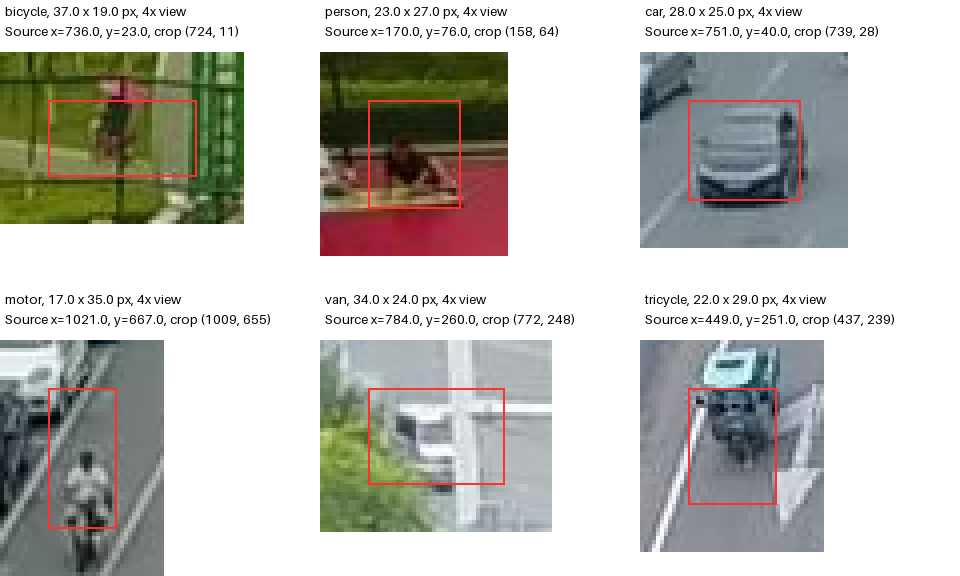

class_name,image_key,x,y,width,height
str,str,f64,f64,f64,f64
"""bicycle""","""train/uav0000084_00000_v/00000…",736.0,23.0,37.0,19.0
"""person""","""train/uav0000084_00000_v/00003…",170.0,76.0,23.0,27.0
"""car""","""train/uav0000124_00944_v/00000…",751.0,40.0,28.0,25.0
"""motor""","""train/uav0000126_00001_v/00001…",1021.0,667.0,17.0,35.0
"""van""","""train/uav0000222_03150_v/00000…",784.0,260.0,34.0,24.0
"""tricycle""","""train/uav0000239_03720_v/00001…",449.0,251.0,22.0,29.0


In [53]:
tiny_objects = (
    objects.filter((pl.col("area") > 0) & (pl.col("area") < 32**2))
    .with_columns(
        (pl.col("area") - pl.col("area").median().over("class_name")).abs().alias("median_distance")
    )
    .sort("median_distance", "image_key", "annotation_id")
    .unique("class_name", keep="first", maintain_order=True)
    .head(6)
)

crops = []

for record in tiny_objects.iter_rows(named=True):
    crops.append(
        draw_crop(
            dataset_root / record["relative_path"],
            tuple((record[key] for key in ("x", "y", "width", "height"))),
            record["class_name"],
        )
    )

if crops:
    cell_width = max((crop.width for crop in crops))
    cell_height = max((crop.height for crop in crops))
    crop_grid = Image.new("RGB", (cell_width * 3, cell_height * 2), "white")
    for index, crop in enumerate(crops):
        crop_grid.paste(crop, (index % 3 * cell_width, index // 3 * cell_height))
    display_image(crop_grid)

tiny_objects.select("class_name", "image_key", "x", "y", "width", "height")

## 5. Objects per frame

The counts include labeled frames with zero targets. We compare the center and tail
of the distribution because dense scenes may need different later sampling and
detection limits. These are dataset properties, not measured detector failures.

In [54]:
density_summary = (
    labeled_frames.group_by("split")
    .agg(
        pl.len().alias("Frames"),
        pl.col("target_count").mean().alias("Mean targets"),
        pl.col("target_count").median().alias("Median targets"),
        pl.col("target_count").quantile(0.95).alias("Targets p95"),
        pl.col("target_count").quantile(0.99).alias("Targets p99"),
        pl.col("target_count").max().alias("Maximum targets"),
        (pl.col("target_count") == 0).sum().alias("Empty target frames"),
    )
    .sort("split")
)

density_summary

split,Frames,Mean targets,Median targets,Targets p95,Targets p99,Maximum targets,Empty target frames
str,u32,f64,f64,f64,f64,u32,u32
"""train""",24201,45.680592,43.0,118.0,142.0,180,3
"""val""",2846,40.1026,37.0,103.0,113.0,116,0


In [55]:
density_bins = (
    labeled_frames.with_columns((pl.col("target_count") // 25 * 25).alias("bin_start"))
    .group_by("split", "bin_start")
    .len(name="frame_count")
    .sort("split", "bin_start")
)

px.bar(
    density_bins,
    x="bin_start",
    y="frame_count",
    color="split",
    barmode="group",
    labels={
        "bin_start": "Targets per frame (25-object bins)",
        "frame_count": "Frames",
        "split": "Split",
    },
    title="Scene density including zero-target frames",
)

In [56]:
clip_density = labeled_frames.group_by("split", "clip").agg(
    pl.len().alias("Frames"),
    pl.col("target_count").mean().alias("Mean targets"),
    pl.col("target_count").median().alias("Median targets"),
    pl.col("target_count").quantile(0.95).alias("Targets p95"),
    pl.col("target_count").max().alias("Maximum targets"),
)

clip_density.sort("Mean targets", descending=True).head(8)

split,clip,Frames,Mean targets,Median targets,Targets p95,Maximum targets
str,str,u32,f64,f64,f64,u32
"""train""","""uav0000138_00000_v""",213,142.962441,150.0,154.0,156
"""train""","""uav0000126_00001_v""",412,132.218447,130.0,153.0,166
"""train""","""uav0000124_00944_v""",398,124.567839,129.0,133.0,134
"""train""","""uav0000072_04488_v""",85,110.376471,108.0,124.0,124
"""train""","""uav0000150_02310_v""",348,108.885057,102.0,158.0,174
"""val""","""uav0000137_00458_v""",233,103.381974,105.0,113.0,116
"""train""","""uav0000279_00001_v""",547,95.347349,108.0,123.0,126
"""train""","""uav0000357_00920_v""",691,91.891462,93.0,102.0,104


## 6. Resolution and split differences

We compare image dimensions for all three splits, then compare label-dependent statistics
only for train and validation. Test resolution and appearance can be inspected without
inventing test labels or selecting model settings from test results.

In [57]:
resolution_counts = frames.group_by("split", "image_width", "image_height").len(name="count")

px.scatter(
    resolution_counts,
    x="image_width",
    y="image_height",
    color="split",
    size="count",
    size_max=45,
    labels={
        "image_width": "Image width (px)",
        "image_height": "Image height (px)",
        "count": "Frames",
        "split": "Split",
    },
    title="Frame resolutions by split",
)

In [58]:
frames.with_columns(
    (pl.col("image_width") / pl.col("image_height")).alias("aspect_ratio")
).group_by("split").agg(
    pl.col("aspect_ratio").min().alias("Min aspect ratio"),
    pl.col("aspect_ratio").median().alias("Median aspect ratio"),
    pl.col("aspect_ratio").max().alias("Max aspect ratio"),
)

split,Min aspect ratio,Median aspect ratio,Max aspect ratio
str,f64,f64,f64
"""test""",1.776119,1.777778,1.780105
"""val""",1.777778,1.777778,1.777778
"""train""",1.777778,1.777778,1.777778


In [59]:
split_sizes = objects.group_by("split").agg(
    pl.col("area").median().alias("Median area px²"),
    (pl.col("size_group") == "Small").mean().alias("Small-object fraction"),
)

density_summary.join(split_sizes, on="split")

split,Frames,Mean targets,Median targets,Targets p95,Targets p99,Maximum targets,Empty target frames,Median area px²,Small-object fraction
str,u32,f64,f64,f64,f64,u32,u32,f64,f64
"""val""",2846,40.1026,37.0,103.0,113.0,116,0,2745.0,0.191971
"""train""",24201,45.680592,43.0,118.0,142.0,180,3,2100.0,0.249066


In [60]:
test_example = (
    frames.filter(pl.col("split") == "test")
    .sort("image_key")
    .sample(n=1, seed=SEED)
    .row(0, named=True)
)

Markdown(
    f"**Unlabeled test example.** `{test_example['image_key']}`, {test_example['image_width']} × {test_example['image_height']} px."
)

**Unlabeled test example.** `test/clip_022/0000089`, 1360 × 764 px.

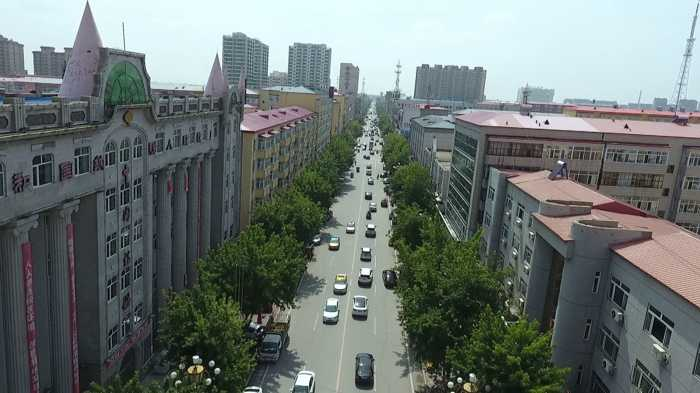

In [61]:
with Image.open(dataset_root / test_example["relative_path"]) as source:
    test_view = source.convert("RGB")
    test_view.thumbnail((700, 450))

display_image(test_view)

## 7. Ignored regions, occlusion, and truncation

The magenta gallery regions are unique COCO crowd geometries. The source COCO repeats
each region across categories, and the table retains those source IDs separately.
We compare the geometries with the
optional ignore text files later. Individual region areas do not measure union coverage,
since regions can overlap. Occlusion and truncation codes below are raw metadata values.
We do not assign ordinal meanings without verifying the source encoding.

In [62]:
ignored_regions.group_by("split").agg(
    pl.len().alias("Ignored regions"),
    pl.col("image_key").n_unique().alias("Frames with regions"),
    pl.col("clip").n_unique().alias("Clips with regions"),
    pl.col("area").median().alias("Median region area px²"),
    pl.col("area").quantile(0.95).alias("Region area p95 px²"),
)

split,Ignored regions,Frames with regions,Clips with regions,Median region area px²,Region area p95 px²
str,u32,u32,u32,f64,f64
"""train""",63843,18090,50,8829.0,98450.0
"""val""",3995,1434,5,10191.0,204120.0


In [63]:
attribute_counts = pl.concat(
    [
        objects.group_by("split", attribute)
        .len(name="count")
        .rename({attribute: "code"})
        .with_columns(
            pl.col("code").cast(pl.String).fill_null("Missing"),
            pl.lit(attribute.capitalize()).alias("attribute"),
        )
        for attribute in ("occlusion", "truncation")
    ]
).with_columns(
    (pl.col("count") / pl.col("count").sum().over("split", "attribute")).alias("fraction")
)

attribute_counts.sort("attribute", "split", "code")

split,code,count,attribute,fraction
str,str,u32,str,f64
"""train""","""0""",600789,"""Occlusion""",0.543447
"""train""","""1""",445799,"""Occlusion""",0.40325
"""train""","""2""",58928,"""Occlusion""",0.053304
"""val""","""0""",46728,"""Occlusion""",0.409421
"""val""","""1""",59822,"""Occlusion""",0.524147
"""val""","""2""",7582,"""Occlusion""",0.066432
"""train""","""0""",1058073,"""Truncation""",0.957085
"""train""","""1""",47443,"""Truncation""",0.042915
"""val""","""0""",108052,"""Truncation""",0.946728


In [64]:
px.bar(
    attribute_counts,
    x="code",
    y="fraction",
    color="split",
    facet_col="attribute",
    barmode="group",
    labels={"code": "Raw annotation code", "fraction": "Target-object fraction", "split": "Split"},
    title="Recorded occlusion and truncation codes",
)

## 8. Video structure and annotation agreement

We inspect clip lengths and adjacent frames, then compare sampled YOLO labels with COCO
using full split, clip, and frame identities. Equal frame filenames in different clips
are not the same image. Text rounding allows a tolerance of 0.01 original-image pixels.

In [65]:
clip_structure = (
    frames.group_by("split", "clip")
    .agg(
        pl.len().alias("Frames"),
        pl.col("frame_id").min().alias("First frame"),
        pl.col("frame_id").max().alias("Last frame"),
        pl.col("frame_id").n_unique().alias("Unique frame IDs"),
    )
    .with_columns(
        (pl.col("Last frame") - pl.col("First frame") + 1 - pl.col("Unique frame IDs")).alias(
            "Frame ID gaps"
        )
    )
)

clip_structure.group_by("split").agg(
    pl.col("Frames").min().alias("Shortest clip"),
    pl.col("Frames").median().alias("Median clip length"),
    pl.col("Frames").max().alias("Longest clip"),
    pl.col("Frame ID gaps").sum().alias("Frame ID gaps"),
)

split,Shortest clip,Median clip length,Longest clip,Frame ID gaps
str,u32,f64,u32,i64
"""val""",184,349.0,978,0
"""train""",58,383.5,1424,0
"""test""",35,73.5,148,0


In [66]:
clip_structure.filter(
    (pl.col("Frame ID gaps") > 0) | (pl.col("Frames") != pl.col("Unique frame IDs"))
).head(8)

split,clip,Frames,First frame,Last frame,Unique frame IDs,Frame ID gaps
str,str,u32,i64,i64,u32,i64


In [67]:
px.scatter(
    clip_density,
    x="Frames",
    y="Mean targets",
    color="split",
    size="Targets p95",
    hover_name="clip",
    labels={
        "Frames": "Frames per clip",
        "Mean targets": "Mean targets per frame",
        "split": "Split",
    },
    title="Clip length and scene density",
)

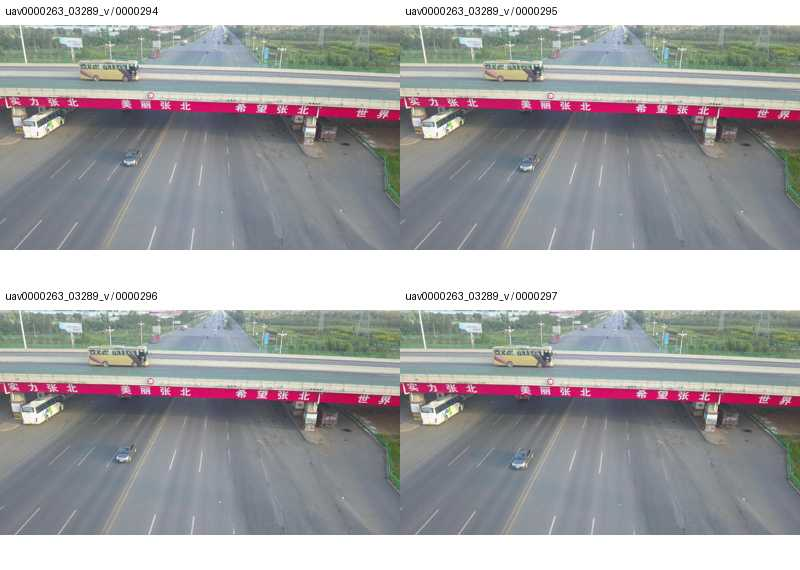

clip,frame,frame_id
str,str,i64
"""uav0000263_03289_v""","""0000294""",294
"""uav0000263_03289_v""","""0000295""",295
"""uav0000263_03289_v""","""0000296""",296
"""uav0000263_03289_v""","""0000297""",297


In [68]:
ordered_frames = frames.filter(pl.col("split") == "train").sort("clip", "frame_id")

consecutive_starts = ordered_frames.filter(
    pl.col("frame_id").shift(-3).over("clip") == pl.col("frame_id") + 3
)

if not consecutive_starts.is_empty():
    start = consecutive_starts.sample(n=1, seed=SEED).row(0, named=True)
    temporal_frames = ordered_frames.filter(
        (pl.col("clip") == start["clip"])
        & pl.col("frame_id").is_between(start["frame_id"], start["frame_id"] + 3)
    )
else:
    clip = ordered_frames["clip"][0]
    temporal_frames = ordered_frames.filter(pl.col("clip") == clip).head(4)

temporal_panels = []

for record in temporal_frames.iter_rows(named=True):
    with Image.open(dataset_root / record["relative_path"]) as source:
        panel = source.convert("RGB")
        panel.thumbnail((400, 260))
    labeled_panel = Image.new("RGB", (400, 285), "white")
    labeled_panel.paste(panel, (0, 25))
    ImageDraw.Draw(labeled_panel).text(
        (5, 5), f"{record['clip']} / {record['frame']}", fill="black"
    )
    temporal_panels.append(labeled_panel)

temporal_grid = Image.new("RGB", (800, 570), "white")

for index, panel in enumerate(temporal_panels):
    temporal_grid.paste(panel, (index % 2 * 400, index // 2 * 285))

display_image(temporal_grid)

temporal_frames.select("clip", "frame", "frame_id")

In [69]:
coordinate_checks = compare_yolo_coco(
    dataset_root, frames, objects, ignored_regions, sample_size=48, seed=SEED
)

coordinate_checks.head(8)

image_key,targets,ignored_regions,max_error_px,is_match
str,i64,i64,f64,bool
"""train/uav0000266_03598_v/00001…",8,2,0.001472,true
"""train/uav0000288_00001_v/00009…",49,0,0.001384,true
"""train/uav0000309_00000_v/00000…",49,0,0.001376,true
"""train/uav0000361_02323_v/00001…",85,6,0.001368,true
"""train/uav0000020_00406_v/00003…",17,1,0.000768,true
"""val/uav0000117_02622_v/0000051""",62,3,0.00192,true
"""train/uav0000342_04692_v/00002…",53,5,0.0012,true
"""val/uav0000086_00000_v/0000083""",37,0,0.000768,true


In [70]:
coordinate_checks.select(
    pl.len().alias("Sampled frames"),
    (~pl.col("is_match")).sum().alias("Mismatched frames"),
    pl.col("max_error_px").max().alias("Maximum error px"),
)

Sampled frames,Mismatched frames,Maximum error px
u32,u32,f64
48,0,0.00256


In [71]:
roundtrip_errors = []

sampled_boxes = objects.sample(n=min(100, objects.height), seed=SEED)

for dimensions, group in sampled_boxes.group_by("image_width", "image_height"):
    width, height = dimensions
    original = group.select("x", "y", "width", "height").to_numpy()
    recovered = yolo_to_xywh(xywh_to_yolo(original, width, height), width, height)
    np.testing.assert_allclose(recovered, original, atol=1e-08)
    roundtrip_errors.append(float(np.abs(original - recovered).max()))

pl.DataFrame({"Maximum round-trip error px": [max(roundtrip_errors, default=0.0)]})

Maximum round-trip error px
f64
2.2737e-13


In [72]:
visual_key = coordinate_checks["image_key"][0]

visual_record = frames.filter(pl.col("image_key") == visual_key).row(0, named=True)

yolo_path = (
    dataset_root
    / visual_record["split"]
    / "labels"
    / visual_record["clip"]
    / f"{visual_record['frame']}.txt"
)

yolo_pixels = read_yolo_boxes(
    yolo_path, visual_record["image_width"], visual_record["image_height"]
)

yolo_table = pl.DataFrame(
    yolo_pixels, schema=["class_id", "x", "y", "width", "height"], orient="row"
).with_columns(pl.col("class_id").cast(pl.Int64))

Markdown(
    f"**Converted YOLO ground truth.** `{visual_key}`. Compare this view with the numeric COCO agreement check."
)

**Converted YOLO ground truth.** `train/uav0000266_03598_v/0000142`. Compare this view with the numeric COCO agreement check.

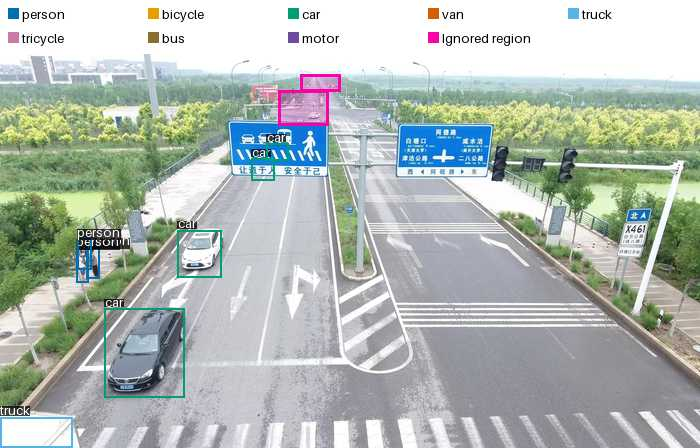

In [73]:
display_image(
    draw_frame(
        dataset_root / visual_record["relative_path"],
        yolo_table,
        ignored_regions.filter(pl.col("image_key") == visual_key),
        max_width=700,
        should_label=len(yolo_pixels) <= 60,
    )
)

## 9. Preprocessing context

The setup has not resized or modified raw data. The tables retain original image
dimensions, pixel boxes, sequence identity, and ignored regions. Any later resize,
padding, tiling, or augmentation must transform boxes explicitly and preserve the
distinction between targets and ignored regions.

We will treat input resolution, small-object sampling, and density-aware inference
limits as hypotheses for later controlled experiments. No detector has been trained
or evaluated here. Test metadata does not determine preprocessing or hyperparameters.

In [74]:
small_fraction = objects.select((pl.col("size_group") == "Small").mean()).item()

median_density = labeled_frames["target_count"].median()

max_density = labeled_frames["target_count"].max()

largest_class = overall_classes.sort("count", descending=True).row(0, named=True)

Markdown(
    f"**Observation.** Small boxes account for {small_fraction:.1%} of target annotations. Labeled frames have a median of {median_density:g} targets and a maximum of {max_density}. The most frequent class is {largest_class['class_name']} at {largest_class['proportion']:.1%}. These are annotation statistics, with repeated appearances of tracked objects counted separately."
)

**Observation.** Small boxes account for 24.4% of target annotations. Labeled frames have a median of 42 targets and a maximum of 180. The most frequent class is car at 44.0%. These are annotation statistics, with repeated appearances of tracked objects counted separately.

In [75]:
Markdown(
    f"**Validation.** Train and validation share {len(overlapping_clips)} clip IDs. We preserve the official validation set and will group any later internal splits by clip. All randomized examples use seed {SEED}."
)

**Validation.** Train and validation share 0 clip IDs. We preserve the official validation set and will group any later internal splits by clip. All randomized examples use seed 2026.